# Recommendation System Project: IBM Community

In this notebook, you will be putting your recommendation skills to use on real data from the IBM Watson Studio platform. 


You may either submit your notebook through the workspace here, or you may work from your local machine and submit through the next page.  Either way assure that your code passes the project [RUBRIC](https://review.udacity.com/#!/rubrics/3325/view).  **Please save regularly.**

By following the table of contents, you will build out a number of different methods for making recommendations that can be used for different situations. 


## Table of Contents

I. [Exploratory Data Analysis](#Exploratory-Data-Analysis)<br>
II. [Rank Based Recommendations](#Rank)<br>
III. [User-User Based Collaborative Filtering](#User-User)<br>
IV. [Content Based Recommendations](#Content-Recs)<br>
V. [Matrix Factorization](#Matrix-Fact)<br>
VI. [Extras & Concluding](#conclusions)

At the end of the notebook, you will find directions for how to submit your work.  Let's get started by importing the necessary libraries and reading in the data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import project_tests as t


df = pd.read_csv(
    'data/user-item-interactions.csv', 
    dtype={'article_id': int, 'title': str, 'email': str}
)
# Show df to get an idea of the data
df.head()

,Unnamed: 0,article_id,title,email
0,0,1430,"using pixiedust for fast, flexible, and easier...",ef5f11f77ba020cd36e1105a00ab868bbdbf7fe7
1,1,1314,healthcare python streaming application demo,083cbdfa93c8444beaa4c5f5e0f5f9198e4f9e0b
2,2,1429,use deep learning for image classification,b96a4f2e92d8572034b1e9b28f9ac673765cd074
3,3,1338,ml optimization using cognitive assistant,06485706b34a5c9bf2a0ecdac41daf7e7654ceb7
4,4,1276,deploy your python model as a restful api,f01220c46fc92c6e6b161b1849de11faacd7ccb2


### <a class="anchor" id="Exploratory-Data-Analysis">Part I : Exploratory Data Analysis</a>

Use the dictionary and cells below to provide some insight into the descriptive statistics of the data.

`1.` Are there any missing values? If so, provide a count of missing values. If there are missing values in `email`, assign it the same id value `"unknown_user"`.

In [2]:
# Some interactions do not have a user associated with it, assume the same user.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45993 entries, 0 to 45992
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  45993 non-null  int64
 1   article_id  45993 non-null  int64
 2   title       45993 non-null  str  
 3   email       45976 non-null  str  
dtypes: int64(2), str(2)
memory usage: 1.4 MB


In [3]:
print(f"Number of Null email values is: {df['email'].isnull().sum()}")

Number of Null email values is: 17


In [4]:
df[df.email.isna()]

,Unnamed: 0,article_id,title,email
25131,25146,1016,why you should master r (even if it might even...,NaN
29758,30157,1393,the nurse assignment problem,NaN
29759,30158,20,working interactively with rstudio and noteboo...,NaN
29760,30159,1174,breast cancer wisconsin (diagnostic) data set,NaN
29761,30160,62,data visualization: the importance of excludin...,NaN
35264,36016,224,"using apply, sapply, lapply in r",NaN
35276,36029,961,beyond parallelize and collect,NaN
35277,36030,268,sector correlations shiny app,NaN
35278,36031,268,sector correlations shiny app,NaN
35279,36032,268,sector correlations shiny app,NaN


In [5]:
# Fill email NaNs with "unknown_user"
df['email'] = df['email'].fillna("unknown_user")


In [6]:
# Check if no more NaNs 
df[df.email.isna()]

,Unnamed: 0,article_id,title,email


`2.` What is the distribution of how many articles a user interacts with in the dataset?  Provide a visual and descriptive statistics to assist with giving a look at the number of times each user interacts with an article.

In [7]:
# What are the descriptive statistics of the number of articles a user interacts with?
user_counts = df.groupby('email')['article_id'].count()
user_counts.describe()

count    5149.000000
mean        8.932414
std        16.801011
min         1.000000
25%         1.000000
50%         3.000000
75%         9.000000
max       364.000000
Name: article_id, dtype: float64

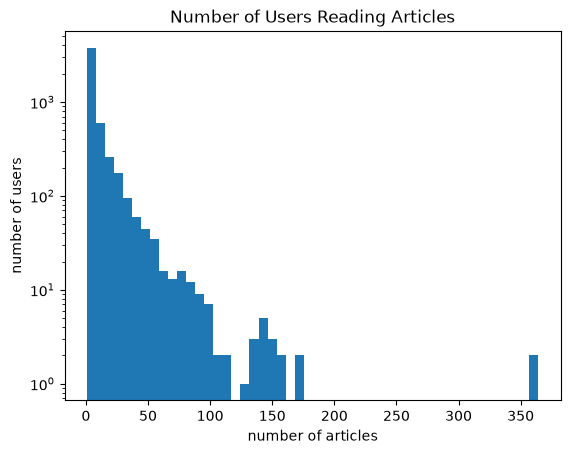

In [8]:
# Create a plot of the number of articles read by each user
plt.hist(user_counts, bins=50)
plt.yscale('log') # Use a logarithmic scale for the y-axis to better visualize the distribution of article reads among users
plt.xlabel('number of articles')
plt.ylabel('number of users')
plt.title('Number of Users Reading Articles')
plt.show()

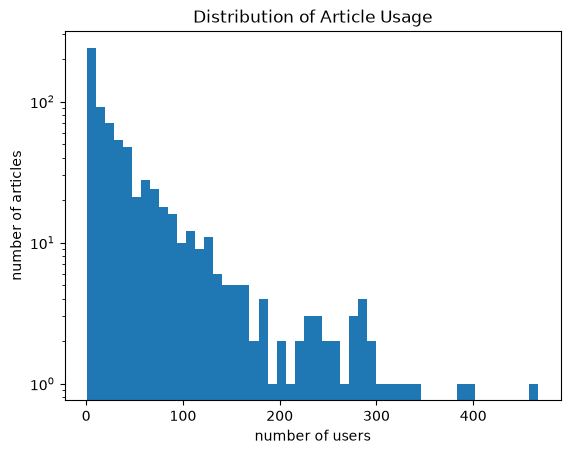

In [9]:
# Create a plot of the number of times each article was read
article_counts = df.groupby('article_id')['email'].nunique()   # number of different users per article
plt.hist(article_counts, bins=50)
plt.yscale('log')   # optional: the long tail is hard to see otherwise
plt.xlabel('number of users')
plt.ylabel('number of articles')
plt.title('Distribution of Article Usage')
plt.show()

In [10]:
df['article_id'].value_counts()

article_id
1429    937
1330    927
1431    671
1427    643
1364    627
       ... 
1237      1
1127      1
675       1
662       1
1233      1
Name: count, Length: 714, dtype: int64

In [11]:
# Fill in the median and maximum number of user_article interactions below
median_val = int(user_counts.median())# 50% of individuals interact with ____ number of articles or fewer.
max_views_by_user = int(user_counts.max()) # The maximum number of user-article interactions by any 1 user is ______.


`3.` Use the cells below to find:

**a.** The number of unique articles that have an interaction with a user.  
**b.** The number of unique articles in the dataset (whether they have any interactions or not).<br>
**c.** The number of unique users in the dataset. (excluding null values) <br>
**d.** The number of user-article interactions in the dataset.

In [12]:
unique_articles = df[df['email'].notna() & (df['email'] != 'unknown_user')]['article_id'].nunique() # The number of unique articles that have at least one interaction
total_articles = df['article_id'].nunique() # The number of unique articles on the IBM platform
unique_users =  df['email'].nunique() # The number of unique users
user_article_interactions = len(df) # The number of user-article interactions

`4.` Use the cells below to find the most viewed **article_id**, as well as how often it was viewed.  After talking to the company leaders, the `email_mapper` function was deemed a reasonable way to map users to ids.  There were a small number of null values, and it was found that all of these null values likely belonged to a single user (which is how they are stored using the function below).

In [13]:
most_viewed_article_id = int(df['article_id'].value_counts().idxmax()) # The most viewed article in the dataset as a string with one value following the decimal 
max_views = int(df['article_id'].value_counts().max()) # The most viewed article in the dataset was viewed how many times?

In [14]:
## No need to change the code here - this will be helpful for later parts of the notebook
# Run this cell to map the user email to a user_id column and remove the email column

def email_mapper(df=df):
    """
    INPUT:
    df - (pandas dataframe) df as defined at the top of the notebook

    OUTPUT:
    user_ids - (list) one integer user id for each row of df; each unique email gets
               its own id, numbered from 1 in order of first appearance
    """
    coded_dict = {
        email: num 
        for num, email in enumerate(df['email'].unique(), start=1)
    }
    return [coded_dict[val] for val in df['email']]

df['user_id'] = email_mapper(df)
del df['email']

# show header
df.head()

,Unnamed: 0,article_id,title,user_id
0,0,1430,"using pixiedust for fast, flexible, and easier...",1
1,1,1314,healthcare python streaming application demo,2
2,2,1429,use deep learning for image classification,3
3,3,1338,ml optimization using cognitive assistant,4
4,4,1276,deploy your python model as a restful api,5


In [15]:
## If you stored all your results in the variable names above, 
## you shouldn't need to change anything in this cell

sol_1_dict = {
    '`50% of individuals have _____ or fewer interactions.`': median_val,
    '`The total number of user-article interactions in the dataset is ______.`': user_article_interactions,
    '`The maximum number of user-article interactions by any 1 user is ______.`': max_views_by_user,
    '`The most viewed article in the dataset was viewed _____ times.`': max_views,
    '`The article_id of the most viewed article is ______.`': most_viewed_article_id,
    '`The number of unique articles that have at least 1 rating ______.`': unique_articles,
    '`The number of unique users in the dataset is ______`': unique_users,
    '`The number of unique articles on the IBM platform`': total_articles
}

# Test your dictionary against the solution
t.sol_1_test(sol_1_dict)

It looks like you have everything right here! Nice job!


### <a class="anchor" id="Rank">Part II: Rank-Based Recommendations</a>

In this project, we don't actually have ratings for whether a user liked an article or not.  We only know that a user has interacted with an article. In these cases, the popularity of an article can really only be based on how often an article was interacted with.

`1.` Fill in the function below to return the **n** top articles ordered with most interactions as the top. Test your function using the tests below.

In [16]:
def get_top_articles(n, df=df):
    """
    INPUT:
    n - (int) the number of top articles to return
    df - (pandas dataframe) df as defined at the top of the notebook 
    
    OUTPUT:
    top_articles - (list) A list of the top 'n' article titles 
    
    """
    top_articles = df['title'].value_counts().head(n).index.tolist()
    
    return top_articles # Return the top article titles from df

def get_top_article_ids(n, df=df):
    """
    INPUT:
    n - (int) the number of top articles to return
    df - (pandas dataframe) df as defined at the top of the notebook 
    
    OUTPUT:
    top_articles - (list) A list of the top 'n' article titles 
    
    """
    top_articles = df['article_id'].value_counts().head(n).index.tolist()
 
    return top_articles # Return the top article ids

In [17]:
print(get_top_articles(10))
print(get_top_article_ids(10))

['use deep learning for image classification', 'insights from new york car accident reports', 'visualize car data with brunel', 'use xgboost, scikit-learn & ibm watson machine learning apis', 'predicting churn with the spss random tree algorithm', 'healthcare python streaming application demo', 'finding optimal locations of new store using decision optimization', 'apache spark lab, part 1: basic concepts', 'analyze energy consumption in buildings', 'gosales transactions for logistic regression model']
[1429, 1330, 1431, 1427, 1364, 1314, 1293, 1170, 1162, 1304]


In [18]:
# Test your function by returning the top 5, 10, and 20 articles
top_5 = get_top_articles(5)
top_10 = get_top_articles(10)
top_20 = get_top_articles(20)

# Test each of your three lists from above
t.sol_2_test(get_top_articles)

Your top_5 looks like the solution list! Nice job.
Your top_10 looks like the solution list! Nice job.
Your top_20 looks like the solution list! Nice job.


### <a class="anchor" id="User-User">Part III: User-User Based Collaborative Filtering</a>


`1.` Use the function below to reformat the **df** dataframe to be shaped with users as the rows and articles as the columns.  

* Each **user** should only appear in each **row** once.


* Each **article** should only show up in one **column**.  


* **If a user has interacted with an article, then place a 1 where the user-row meets for that article-column**.  It does not matter how many times a user has interacted with the article, all entries where a user has interacted with an article should be a 1.  


* **If a user has not interacted with an item, then place a zero where the user-row meets for that article-column**. 

Use the tests to make sure the basic structure of your matrix matches what is expected by the solution.

In [19]:
# create the user-article matrix with 1's and 0's

def create_user_item_matrix(df, fill_value=0):
    """
    INPUT:
    df - pandas dataframe with article_id, title, user_id columns
    
    OUTPUT:
    user_item - user item matrix 
    
    Description:
    Return a matrix with user ids as rows and article ids on the columns with 1 values where a user interacted with 
    an article and a 0 otherwise
    """
    user_item = (
        df.drop_duplicates(subset=['user_id', 'article_id'])
          .assign(interaction=1)
          .pivot(index='user_id', columns='article_id', values='interaction')
          .fillna(fill_value)
          .astype(int)
    )

    return user_item # return the user_item matrix 

user_item = create_user_item_matrix(df)

In [20]:
## Tests: You should just need to run this cell.  Don't change the code.
assert user_item.shape[0] == 5149, "Oops!  The number of users in the user-article matrix doesn't look right."
assert user_item.shape[1] == 714, "Oops!  The number of articles in the user-article matrix doesn't look right."
assert user_item.sum(axis=1)[1] == 36, "Oops!  The number of articles seen by user 1 doesn't look right."
print("You have passed our quick tests!  Please proceed!")

print()

You have passed our quick tests!  Please proceed!



`2.` Complete the function below which should take a user_id and provide an ordered list of the most similar users to that user (from most similar to least similar).  The returned result should not contain the provided user_id, as we know that each user is similar to him/herself. Because the results for each user here are binary, it (perhaps) makes sense to compute similarity as the dot product of two users. 

Use the tests to test your function.

In [21]:
# Lets use the cosine_similarity function from sklearn
from sklearn.metrics.pairwise import cosine_similarity

In [22]:
def find_similar_users(user_id, user_item=user_item, include_similarity=False):
    """
    INPUT:
    user_id - (int) a user_id
    user_item - (pandas dataframe) matrix of users by articles: 
                1's when a user has interacted with an article, 0 otherwise
    include_similarity - (bool) whether to include the similarity in the output
    
    OUTPUT:
    similar_users - (list) an ordered list where the closest users (highest cosine similarity)
                    are listed first
    
    Description:
    Computes the cosine similarity between the given user and every other user
    Returns an ordered list of user ids. If include_similarity is True, returns a list of lists
    where the first element is the user id and the second the similarity.
    
    """
    
    # compute similarity of each user to the provided user
    sims = cosine_similarity(user_item, user_item.loc[[user_id]]).ravel()
    similarity = pd.Series(sims, index=user_item.index)

    # remove the own user's id
    similarity = similarity.drop(user_id)

    # sort by similarity
    similarity = similarity.sort_values(ascending=False)
    
    # create list of just the ids
    most_similar_users = similarity.index.tolist()
    
    # create list of just the similarities
    most_similarities = similarity.values.tolist()
    
    if include_similarity:
        return [[user, sim] for user, sim in zip(most_similar_users, most_similarities)] # return a list of lists with [[similar_user_id, similarity], ...]
    return most_similar_users # return a list of the users in order from most to least similar
        

In [23]:
# Do a spot check of your function
print("The 10 most similar users to user 1 are: {}".format(find_similar_users(1)[:10]))
print("The 5 most similar users to user 3933 are: {}".format(find_similar_users(3933)[:5]))
print("The 3 most similar users to user 46 are: {}".format(find_similar_users(46)[:3]))

The 10 most similar users to user 1 are: [3933, 4201, 46, 253, 824, 5034, 5041, 136, 2305, 395]
The 5 most similar users to user 3933 are: [1, 4201, 46, 253, 5034]
The 3 most similar users to user 46 are: [4201, 790, 5077]


`3.` Now that you have a function that provides the most similar users to each user, you will want to use these users to find articles you can recommend.  Complete the functions below to return the articles you would recommend to each user. 

In [24]:
def get_article_names(article_ids, df=df):
    """
    INPUT:
    article_ids - (list) a list of article ids
    df - (pandas dataframe) df as defined at the top of the notebook
    
    OUTPUT:
    article_names - (list) a list of article names associated with the list of article ids 
                    (this is identified by the title column in df)
    """
    # Your code here
    id_to_title = df.drop_duplicates(subset='article_id').set_index('article_id')['title']
    
    article_names = id_to_title.loc[article_ids].tolist()
    return article_names # Return the article names associated with list of article ids

def get_ranked_article_unique_counts(article_ids, user_item=user_item):
    """
    INPUT:
    article_ids - (list) a list of article ids to evaluate (a subset to rank).
                the dtype should match the column labels in `user_item`.
    user_item - (pandas dataframe) a binary matrix of users by articles [n_users x n_articles]:
                1's when a user has interacted with an article, 0 otherwise 
                columns are article IDs.
    
    OUTPUT:
    ranked_article_unique_counts - (list) a list of [article_id, unique_user_count] pairs
                     only for the provided `article_ids` with article_id and number of unique
                     users that have interacted with the article, sorted by the number of unique
                     users in descending order
    
    Description:
    For each `article_id` in the input list, count the number of unique users who
    interacted with it (column sum in the binary `user_item` matrix).
    Return the [article_id, count] pairs sorted in descending order.
    """
    # Your code here
    counts = user_item[article_ids].sum().sort_values(ascending=False)
    ranked_article_unique_counts = [[int(a), int(c)] for a, c in counts.items()]
    return ranked_article_unique_counts


def get_user_article_ids(user_id, user_item=user_item):
    """
    INPUT:
    user_id - (int) a user id
    user_item - (pandas dataframe) matrix of users by articles: 
                1's when a user has interacted with an article, 0 otherwise
    
    OUTPUT:
    article_ids - (list) a list of the article ids the user has interacted with
    """
    user_row = user_item.loc[user_id]
    return user_row[user_row == 1].index.tolist()


def get_user_articles(user_id, user_item=user_item):
    """
    INPUT:
    user_id - (int) a user id
    user_item - (pandas dataframe) matrix of users by articles: 
                1's when a user has interacted with an article, 0 otherwise
    
    OUTPUT:
    article_ids - (list) a list of the article ids seen by the user
    article_names - (list) a list of article names associated with the list of article ids 
                    (this is identified by the title column in df)
    
    Description:
    Provides a list of the article_ids and article titles that have been seen by a user
    """
    # Your code here
    article_ids = get_user_article_ids(user_id, user_item=user_item)
    article_names = get_article_names(article_ids)
    return article_ids, article_names # return the ids and names


def user_user_recs(user_id, m=10, user_item=user_item):
    """
    INPUT:
    user_id - (int) a user id
    m - (int) the number of recommendations you want for the user
    
    OUTPUT:
    recs - (list) a list of recommendations for the user
    
    Description:
    Loops through the users based on closeness to the input user_id
    For each user - finds articles the user hasn't seen before and provides them as recs
    Does this until m recommendations are found
    
    Notes:
    Users who are the same closeness are chosen arbitrarily as the 'next' user
    
    For the user where the number of recommended articles starts below m 
    and ends exceeding m, the last items are chosen arbitrarily
    
    """
    # Your code here
    seen = set(get_user_article_ids(user_id, user_item=user_item))
    recs = []

    for neighbor in find_similar_users(user_id, user_item=user_item):
        neighbor_articles = get_user_article_ids(neighbor, user_item=user_item)
        new_articles = [a for a in neighbor_articles if a not in seen]
        recs.extend(new_articles)
        seen.update(new_articles)

        if len(recs) >= m:
            break

    return recs[:m] # return your recommendations for this user_id    

In [25]:
# Check Results
get_article_names(user_user_recs(1, 10)) # Return 10 recommendations for user 1

['this week in data science (april 18, 2017)',
 'this week in data science (may 2, 2017)',
 'top 20 r machine learning and data science packages',
 'improving the roi of big data and analytics through leveraging new sources of data',
 'using apply, sapply, lapply in r',
 'awesome deep learning papers',
 'leverage python, scikit, and text classification for behavioral profiling',
 'challenges in deep learning',
 'do i need to learn r?',
 'how can data scientists collaborate to build better business']

In [26]:
get_ranked_article_unique_counts([1320, 232, 844])

[[1320, 123], [844, 78], [232, 62]]

In [27]:
# Test your functions here - No need to change this code - just run this cell
assert set(get_article_names([1024, 1176, 1305, 1314, 1422, 1427])) == set(['using deep learning to reconstruct high-resolution audio', 'build a python app on the streaming analytics service', 'gosales transactions for naive bayes model', 'healthcare python streaming application demo', 'use r dataframes & ibm watson natural language understanding', 'use xgboost, scikit-learn & ibm watson machine learning apis']), "Oops! Your the get_article_names function doesn't work quite how we expect."
assert set(get_article_names([1320, 232, 844])) == set(['housing (2015): united states demographic measures','self-service data preparation with ibm data refinery','use the cloudant-spark connector in python notebook']), "Oops! Your the get_article_names function doesn't work quite how we expect."
assert set(get_user_articles(20)[0]) == set([1320, 232, 844])
assert set(get_user_articles(20)[1]) == set(['housing (2015): united states demographic measures', 'self-service data preparation with ibm data refinery','use the cloudant-spark connector in python notebook'])
assert set(get_user_articles(2)[0]) == set([1024, 1176, 1305, 1314, 1422, 1427])
assert set(get_user_articles(2)[1]) == set(['using deep learning to reconstruct high-resolution audio', 'build a python app on the streaming analytics service', 'gosales transactions for naive bayes model', 'healthcare python streaming application demo', 'use r dataframes & ibm watson natural language understanding', 'use xgboost, scikit-learn & ibm watson machine learning apis'])
assert get_ranked_article_unique_counts([1320, 232, 844])[0] == [1320, 123], "Oops! Your the get_ranked_article_unique_counts function doesn't work quite how we expect.\nMake sure you are using the user_item matrix to create the article counts."
print("If this is all you see, you passed all of our tests!  Nice job!")

If this is all you see, you passed all of our tests!  Nice job!


`4.` Now we are going to improve the consistency of the **user_user_recs** function from above.  

* Instead of arbitrarily choosing when we obtain users who are all the same closeness to a given user - choose the users that have the most total article interactions before choosing those with fewer article interactions.


* Instead of arbitrarily choosing articles from the user where the number of recommended articles starts below m and ends exceeding m, choose articles with the articles with the most total interactions before choosing those with fewer total interactions. This ranking should be  what would be obtained from the **top_articles** function you wrote earlier.

In [28]:
def get_top_sorted_users(user_id, user_item=user_item):
    """
    INPUT:
    user_id - (int)
    user_item - (pandas dataframe) matrix of users by articles: 
            1's when a user has interacted with an article, 0 otherwise
    
            
    OUTPUT:
    neighbors_df - (pandas dataframe) a dataframe with:
                    neighbor_id - is a neighbor user_id
                    similarity - measure of the similarity of each user to the provided user_id
                    num_interactions - the number of articles viewed by the user
                    
    Other Details - sort the neighbors_df by the similarity and then by number of interactions where 
                    highest of each is higher in the dataframe, i.e. Descending order
     
    """
    # Your code here
    # Hint: find similar users, but include their similarity, from there we can find the number of interactions for each neighbor
    neighbors = find_similar_users(user_id, user_item=user_item, include_similarity=True)
    neighbors_df = pd.DataFrame(neighbors, columns=['neighbor_id', 'similarity'])
    neighbors_df['num_interactions'] = user_item.sum(axis=1).loc[neighbors_df['neighbor_id']].values
    neighbors_df = neighbors_df.sort_values(by=['similarity', 'num_interactions'], ascending=False).reset_index(drop=True)
    return neighbors_df # Return the dataframe specified in the doc_string


def user_user_recs_part2(user_id, m=10, user_item=user_item, df=df):
    """
    INPUT:
    user_id - (int) a user id
    m - (int) the number of recommendations you want for the user
    
    OUTPUT:
    recs - (list) a list of recommendations for the user by article id
    rec_names - (list) a list of recommendations for the user by article title
    
    Description:
    Loops through the users based on closeness to the input user_id
    For each user - finds articles the user hasn't seen before and provides them as recs
    Does this until m recommendations are found
    
    Notes:
    * Choose the users that have the most total article interactions 
    before choosing those with fewer article interactions.

    * Choose articles with the articles with the most total interactions 
    before choosing those with fewer total interactions. 
   
    """
    # Your code here
    seen = set(get_user_article_ids(user_id, user_item=user_item))
    recs = []

    neighbors = get_top_sorted_users(user_id, user_item=user_item)['neighbor_id']

    for neighbor in neighbors:
        unseen = [a for a in get_user_article_ids(neighbor, user_item=user_item)
                  if a not in seen]
        ranked_ids = [a for a, _ in get_ranked_article_unique_counts(unseen, user_item=user_item)]

        recs.extend(ranked_ids)
        seen.update(ranked_ids)

        if len(recs) >= m:
            break

    recs = recs[:m]
    return recs, get_article_names(recs, df=df) # return your recommendations for this user_id

In [29]:
# Quick spot check - don't change this code - just use it to test your functions
rec_ids, rec_names = user_user_recs_part2(20, 10)
print("The top 10 recommendations for user 20 are the following article ids:")
print(rec_ids)
print()
print("The top 10 recommendations for user 20 are the following article names:")
print(rec_names)

The top 10 recommendations for user 20 are the following article ids:
[1185, 1165, 1293, 254, 1162, 1271, 1328, 1410, 40, 1402]

The top 10 recommendations for user 20 are the following article names:
['classify tumors with machine learning', 'analyze precipitation data', 'finding optimal locations of new store using decision optimization', 'apple, ibm add machine learning to partnership with watson-core ml coupling', 'analyze energy consumption in buildings', 'customer demographics and sales', 'income (2015): united states demographic measures', 'uci: sms spam collection', 'ensemble learning to improve machine learning results', 'uci: adult - predict income']


`5.` Use your functions from above to correctly fill in the solutions to the dictionary below.  Then test your dictionary against the solution.  Provide the code you need to answer each following the comments below.

In [30]:
print(get_top_sorted_users(1, user_item=user_item).head(n=1))
print(get_top_sorted_users(2, user_item=user_item).head(n=10))
print(get_top_sorted_users(131, user_item=user_item).head(n=10))

   neighbor_id  similarity  num_interactions
0         3933    0.986013                35
   neighbor_id  similarity  num_interactions
0         5083    0.730297                 5
1         1552    0.577350                 2
2         1890    0.577350                 2
3         1372    0.471405                 3
4         2941    0.433013                 8
5         3586    0.408248                 4
6         2595    0.408248                 1
7          331    0.408248                 1
8         2597    0.408248                 1
9          701    0.408248                 1
   neighbor_id  similarity  num_interactions
0         3870    0.986667                75
1          203    0.388909                96
2         4459    0.388909                96
3         3782    0.387585               135
4           40    0.384308                52
5         4932    0.384308                52
6           23    0.377647               135
7          242    0.375823                59
8         

In [31]:
### Tests with a dictionary of results
user1_most_sim = int(get_top_sorted_users(1).iloc[0]['neighbor_id'])# Find the user that is most similar to user 1 
user2_6th_sim = int(get_top_sorted_users(2).iloc[5]['neighbor_id'])# Find the 6th most similar user to user 2
user131_10th_sim = int(get_top_sorted_users(131).iloc[9]['neighbor_id'])# Find the 10th most similar user to user 131

In [32]:
## Dictionary Test Here
sol_5_dict = {
    'The user that is most similar to user 1.': user1_most_sim, 
    'The user that is the 6th most similar to user 2.': user2_6th_sim,
    'The user that is the 10th most similar to user 131.': user131_10th_sim,
}

t.sol_5_test(sol_5_dict)

This all looks good!  Nice job!


`6.` If we were given a new user, which of the above functions would you be able to use to make recommendations?  Explain.  Can you think of a better way we might make recommendations?  Use the cell below to explain a better method for new users.

**Which functions can be used for a new user?**

For a brand-new user, only the rank-based functions (`get_top_articles` and `get_top_article_ids`) can make recommendations. The user-user collaborative filtering functions (`find_similar_users`, `user_user_recs` and `user_user_recs_part2`) can't. They compare a user's reading history with other users' histories, and a new user has none. Their row in `user_item` would be all zeros, so cosine similarity would be undefined or meaningless and no neighbors could be found.

**A better approach**

Rank-based recommendations give every new user the same list, so a better approach is to personalise as quickly as possible:

- **Ask for preferences at sign-up.** Let the user pick topics or interests, then recommend popular articles from those topics, using the title clusters from the content-based method.
- **Use content-based recommendations after the first interaction.** As soon as the user views one article, recommend similar articles by title. This needs only one article of history, not a whole user profile.
- **Blend with popularity.** Rank the similar articles by popularity, as `make_content_recs` does, so the recommendations are both relevant and well liked.
- **Switch to collaborative filtering once there's enough history.** After a few interactions, user-user filtering or matrix factorization has enough data to find real neighbors.

`7.` Using your existing functions, provide the top 10 recommended articles you would provide for the a new user below.  You can test your function against our thoughts to make sure we are all on the same page with how we might make a recommendation.

In [33]:
# What would your recommendations be for this new user 0?  As a new user, they have no observed articles.
# Provide a list of the top 10 article ids you would give to 
new_user_recs = get_top_article_ids(10)# Your recommendations here

In [34]:
assert set(new_user_recs) == {1314, 1429, 1293, 1427, 1162, 1364, 1304, 1170, 1431, 1330}, "Oops!  It makes sense that in this case we would want to recommend the most popular articles, because we don't know anything about these users."

print("That's right!  Nice job!")

That's right!  Nice job!


### <a class="anchor" id="Content-Recs">Part IV: Content Based Recommendations</a>

Another method we might use to make recommendations is to recommend similar articles that are possibly related. One way we can find article relationships is by clustering text about those articles.  Let's consider content to be the article **title**, as it is the only text we have available. One point to highlight, there isn't one way to create a content based recommendation, especially considering that text information can be processed in many ways.  

`1.` Use the function bodies below to create a content based recommender function `make_content_recs`. We'll use TF-IDF to create a matrix based off article titles, and use this matrix to create clusters of related articles. You can use this function to make recommendations of new articles.

In [35]:
df.head()

,Unnamed: 0,article_id,title,user_id
0,0,1430,"using pixiedust for fast, flexible, and easier...",1
1,1,1314,healthcare python streaming application demo,2
2,2,1429,use deep learning for image classification,3
3,3,1338,ml optimization using cognitive assistant,4
4,4,1276,deploy your python model as a restful api,5


In [36]:
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from sklearn.decomposition import TruncatedSVD

In [37]:
# unique articles
df_unique_articles = df.drop_duplicates(subset='article_id').reset_index(drop=True)

In [38]:
# Create a vectorizer using TfidfVectorizer and fit it to the article titles
max_features = 200
max_df = 0.75
min_df = 5

vectorizer = TfidfVectorizer(
    max_df=max_df,
    min_df=min_df,
    stop_words="english",
    max_features=max_features,
)
print("Running TF-IDF")
X_tfidf = vectorizer.fit_transform(df_unique_articles['title']) # Fit the vectorizer to the article titles

print(f"n_samples: {X_tfidf.shape[0]}, n_features: {X_tfidf.shape[1]}")

lsa = make_pipeline(TruncatedSVD(n_components=50), Normalizer(copy=False))
X_lsa = lsa.fit_transform(X_tfidf) # Fit the LSA model to the vectorized article titles
explained_variance = lsa[0].explained_variance_ratio_.sum()

print(f"Explained variance of the SVD step: {explained_variance * 100:.1f}%")

Running TF-IDF
n_samples: 714, n_features: 125
Explained variance of the SVD step: 76.0%


Text(0.5, 0, 'Number of clusters')

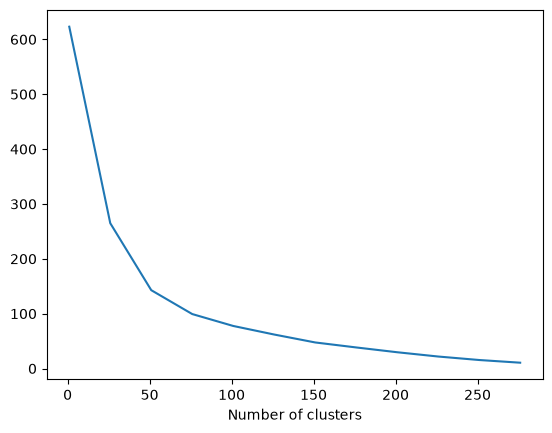

In [39]:
# Let's map the inertia for different number of clusters to find the optimal number of clusters
# We'll plot it to see the elbow
inertia = []
clusters = 300
step = 25
max_iter = 50
n_init = 5
random_state = 42
for k in range(1, clusters, step):
    kmeans = KMeans(
        n_clusters=k,
        max_iter=max_iter,
        n_init=n_init,
        random_state=random_state,
    ).fit(X_lsa)
    # inertia is the sum of squared distances to the closest cluster center
    inertia.append(kmeans.inertia_)
plt.plot(range(1, clusters, step), inertia)
plt.xlabel('Number of clusters')

There appears to be an elbow about 50, so we'll use 50 clusters.

In [40]:
n_clusters = 50
kmeans = KMeans(
    n_clusters=n_clusters,
    max_iter=max_iter,
    n_init=n_init,
    random_state=random_state,
).fit(X_lsa)

In [41]:
# create a new column `title_cluster` and assign it the kmeans cluster labels
# First we need to map the labels to df_unique_articles article ids and then apply those to df
article_cluster_map = dict(zip(df_unique_articles['article_id'], kmeans.labels_)) # Map article_id to cluster label
df['title_cluster'] = df['article_id'].map(article_cluster_map) # apply map to create title clusters

In [42]:
# Let's check the number of articles in each cluster
np.array(np.unique(kmeans.labels_, return_counts=True)).T

array([[ 0, 11],
       [ 1, 13],
       [ 2, 62],
       [ 3, 23],
       [ 4, 16],
       [ 5,  9],
       [ 6, 37],
       [ 7,  8],
       [ 8, 28],
       [ 9, 20],
       [10, 15],
       [11, 10],
       [12, 29],
       [13,  8],
       [14,  7],
       [15,  6],
       [16, 29],
       [17, 20],
       [18, 19],
       [19, 17],
       [20, 19],
       [21, 14],
       [22, 10],
       [23, 14],
       [24, 13],
       [25, 11],
       [26,  7],
       [27, 12],
       [28, 35],
       [29,  7],
       [30, 11],
       [31,  7],
       [32, 22],
       [33,  8],
       [34,  8],
       [35, 10],
       [36,  6],
       [37, 10],
       [38,  9],
       [39,  8],
       [40,  9],
       [41,  6],
       [42, 14],
       [43, 10],
       [44,  5],
       [45,  7],
       [46,  7],
       [47, 14],
       [48,  8],
       [49,  6]])

In [43]:
def get_similar_articles(article_id, df=df):
    """
    INPUT:
    article_id - (int) an article id 
    df - (pandas dataframe) df as defined at the top of the notebook 
    
    OUTPUT:
    article_ids - (list) a list of article ids that are in the same title cluster
    
    Description:
    Returns a list of the article ids that are in the same title cluster
    """
     # Your code here
    title_cluster = df.loc[df['article_id'] == article_id, 'title_cluster'].iloc[0]
    articles_in_cluster = df.loc[df['title_cluster'] == title_cluster, 'article_id'].unique().tolist()
    
    # remove the input article_id from the list
    articles_in_cluster.remove(article_id)

    return articles_in_cluster

In [44]:
def make_content_recs(article_id, n, df=df, user_item=user_item):
    """
    INPUT:
    article_id - (int) an article id
    n - (int) the number of recommendations you want similar to the article id
    df - (pandas dataframe) df as defined at the top of the notebook
    
    OUTPUT:
    n_ranked_similar_articles - (list) a list of article ids that are in the same title cluster ranked
                                by popularity
    n_ranked_article_names - (list) a list of article names associated with the list of article ids
    
    Description:
    Returns a list of the n most ranked similar articles to a given article_id based on the title
    cluster in df. Rank similar articles using the function get_ranked_article_unique_counts.
    """
    # Your code here
    similar_articles = get_similar_articles(article_id, df=df)
    ranked = get_ranked_article_unique_counts(similar_articles, user_item=user_item)
    n_ranked_similar_articles = [a for a, count in ranked[:n]]
    n_ranked_article_names = get_article_names(n_ranked_similar_articles, df=df)
    return n_ranked_similar_articles, n_ranked_article_names
        

In [45]:
# Test out your content recommendations given artice_id 25
rec_article_ids, rec_article_titles = make_content_recs(25, 10)
print(rec_article_ids)
print(rec_article_titles)

[1025, 593, 349, 821, 464, 29, 1042, 634, 693, 146]
['data tidying in data science experience', 'upload files to ibm data science experience using the command line', 'ibm data science experience white paper - sparkr transforming r into a tool for big data analytics', 'using rstudio in ibm data science experience', 'use ibm data science experience to detect time series anomalies', 'experience iot with coursera', 'use ibm data science experience to read and write data stored on amazon s3', 'working with db2 warehouse on cloud in data science experience', 'better together: spss and data science experience', 'how to use db2 warehouse on cloud in data science experience notebooks']


In [46]:
assert len({1025, 593, 349, 821, 464, 29, 1042, 693, 524, 352}.intersection(set(rec_article_ids))) > 0, "Oops! Your the make_content_recs function doesn't work quite how we expect."

print("That's right!  Your make_content_recs function works as expected.")

That's right!  Your make_content_recs function works as expected.


`2.` Now that you have put together your content-based recommendation system, use the cell below to write a summary explaining how your content based recommender works.  Do you see any possible improvements that could be made to your function? What other text data would be useful to help make better recommendations besides the article title?

**How the content-based recommender works**

The recommender uses only the article titles, because that's the only text in the data.

1. **Turn titles into numbers.** `TfidfVectorizer` converts each of the 714 unique article titles into a vector with one value per word. English stop words are removed. Words that appear in fewer than 5 titles are dropped, which reduces about 1,300 distinct words to 125. A word scores higher when it is rare across titles, so it helps tell titles apart.
2. **Compress the vectors.** `TruncatedSVD` (latent semantic analysis) reduces the 125 word columns to 50 topic columns, keeping about 76% of the variation. This groups words that appear together, so titles on the same subject end up close even when they use different words. A `Normalizer` then scales each vector to length 1, so only the topic mix matters and the title's length doesn't.
3. **Cluster the articles.** KMeans groups the 714 articles into 50 clusters. The number 50 comes from the elbow in the inertia plot. Articles in the same cluster have similar titles.
4. **Recommend.** `make_content_recs` takes an article, finds all the other articles in its cluster, ranks them by how many unique users have viewed them (`get_ranked_article_unique_counts`), and returns the top `n` with their titles. The popularity ranking puts well-liked articles first.

**Possible improvements**

- **Don't use hard cluster boundaries.** An article near the edge of a cluster is treated as unrelated to a very close neighbor in the next cluster. Instead, rank articles by cosine similarity in the LSA space (`X_lsa`) and take the nearest ones. The similarity score could also be combined with popularity, so that a very popular article that is only slightly similar doesn't always beat a closer match.
- **Tune the text processing.** `min_df=5` throws away most of the vocabulary. Trying bigrams (`ngram_range=(1, 2)`), such as "machine learning", and tuning `min_df` and the number of clusters could give better groups.
- **Use better text representations.** Pre-trained sentence embeddings capture meaning that TF-IDF misses, such as "car" and "automobile".
- **Personalise it.** The current version only uses one article. It could use all the articles a user has read, for example by averaging their vectors, and it could remove articles the user has already seen.
- **Evaluate it.** There's no measure of whether the recommendations are good. We could check, for example, how often a user actually reads a recommended article.

**Other text data that would help**

Titles are short, so the clusters are coarse. More useful text would be:
- the full article text or a summary/abstract,
- tags, keywords or topic categories,
- the author, and the type of article (tutorial, notebook, news),
- the publication date, since recent articles may be more relevant.

Any of these would give the model much more to compare than a handful of words in a title. A bonus is that this approach works for new articles with no views, which collaborative filtering cannot handle.

### <a class="anchor" id="Matrix-Fact">Part V: Matrix Factorization</a>

In this part of the notebook, you will build use matrix factorization to make article recommendations to users.

`1.` You should have already created a **user_item** matrix above in **question 1** of **Part III** above.  This first question here will just require that you run the cells to get things set up for the rest of **Part V** of the notebook. 

In [47]:
# quick look at the matrix
user_item.head()

article_id,0,2,4,8,9,12,14,15,16,18,...,1434,1435,1436,1437,1439,1440,1441,1442,1443,1444
user_id,,,,,,,,,,,,,,,,,,,,,
1,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,1,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


`2.` In this situation, you can use Singular Value Decomposition from [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html) on the user-item matrix.  Use the cell to perform SVD.

In [48]:
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import precision_score, recall_score, accuracy_score
# Using the full number of components which equals the number of columns
svd = TruncatedSVD(n_components=len(user_item.columns), n_iter=5, random_state=42)

u = svd.fit_transform(user_item)
v = svd.components_
s = svd.singular_values_ 
print('u', u.shape)
print('s', s.shape)
print('vt', v.shape)

u (5149, 714)
s (714,)
vt (714, 714)


**Why SVD works in this case**

Singular value decomposition factorises the user-item matrix (5,149 users × 714 articles) into three matrices that multiply back to (approximately) the original:

- **U** (users × latent features): how strongly each user is associated with each latent feature.
- **Σ** (sigma, one value per latent feature): how important each latent feature is, ordered from most to least important.
- **Vᵀ** (latent features × articles): which articles make up each latent feature.

In the code above, `u` is what scikit-learn returns from `fit_transform`, which is U already multiplied by Σ. `s` holds the singular values (the diagonal of Σ), and `v` is Vᵀ. Multiplying `u` by `v` gives back the user-item matrix, which is what the next cell does.

The technique works here because the user-item matrix has **no missing values**: every cell is a 1 (the user interacted with the article) or a 0 (they did not), so the matrix can be decomposed directly. Classic SVD can't handle missing (NaN) values, and a different method such as FunkSVD would be needed for ratings that are mostly unknown. Each latent feature picks up a group of articles that tend to be read by the same users, so keeping only the strongest features compresses the matrix and drops the noise from one-off reads. Articles with similar columns in Vᵀ are read by similar users, which is how `get_svd_similar_article_ids` finds similar articles.

One limit: a 0 means "not read", not "disliked", so the reconstructed matrix can only suggest articles a user might also read.

`3.` Now for the tricky part, how do we choose the number of latent features to use?  Running the below cell, you can see that as the number of latent features increases, we obtain better metrics when making predictions for the 1 and 0 values in the user-item matrix.  Run the cell below to get an idea of how our metrics improve as we increase the number of latent features.

Text(0.5, 1.0, 'Metrics vs. Number of Latent Features')

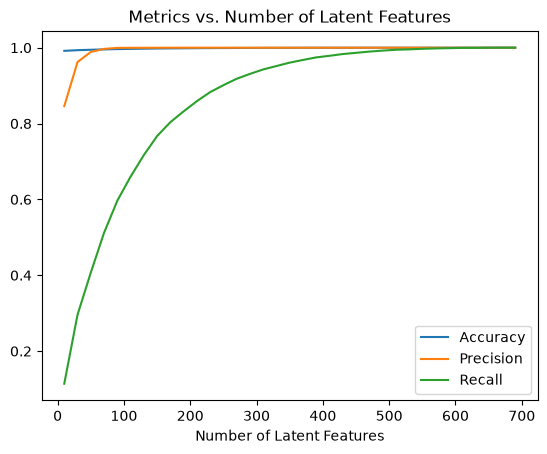

In [49]:
num_latent_feats = np.arange(10, 700+10, 20)
metric_scores = []

for k in num_latent_feats:
    # restructure with k latent features
    u_new, vt_new = u[:, :k], v[:k, :]
    
    # take dot product
    user_item_est = abs(np.around(np.dot(u_new, vt_new))).astype(int)
    # make sure the values are between 0 and 1
    user_item_est = np.clip(user_item_est, 0, 1)
    
    # total errors and keep track of them
    acc = accuracy_score(user_item.values.flatten(), user_item_est.flatten())
    precision = precision_score(user_item.values.flatten(), user_item_est.flatten())
    recall = recall_score(user_item.values.flatten(), user_item_est.flatten())
    metric_scores.append([acc, precision, recall])
    
    
plt.plot(num_latent_feats, metric_scores, label=['Accuracy', 'Precision', 'Recall'])
plt.legend()
plt.xlabel('Number of Latent Features')
plt.title('Metrics vs. Number of Latent Features')

In [50]:
# Print the exact scores behind the plot so the choice of 200 latent features is backed by numbers
scores_df = pd.DataFrame(metric_scores, columns=['Accuracy', 'Precision', 'Recall'], index=num_latent_feats)
scores_df.index.name = 'Latent features'

# The plot only evaluates every 20th value (10, 30, ..., 690), so 200 is not in the grid; score it directly
k = 200
est = np.clip(abs(np.around(np.dot(u[:, :k], v[:k, :]))).astype(int), 0, 1)
y_true, y_pred = user_item.values.flatten(), est.flatten()
scores_df.loc[k] = [accuracy_score(y_true, y_pred), precision_score(y_true, y_pred), recall_score(y_true, y_pred)]
scores_df = scores_df.sort_index()

# Baseline: always predicting 0 (no interaction)
print(f"All-zeros baseline accuracy: {1 - y_true.mean():.4f}\n")
print(scores_df.loc[[10, 50, 110, 190, 200, 210, 310, 510, 690]].round(4))

All-zeros baseline accuracy: 0.9908

                 Accuracy  Precision  Recall
Latent features                             
10                 0.9917     0.8460  0.1142
50                 0.9945     0.9887  0.4070
110                0.9969     0.9997  0.6600
190                0.9985     1.0000  0.8321
200                0.9986     1.0000  0.8456
210                0.9987     1.0000  0.8590
310                0.9995     1.0000  0.9427
510                0.9999     1.0000  0.9945
690                1.0000     1.0000  1.0000


`4.` From the above, we can't really be sure how many features to use, because simply having a better way to predict the 1's and 0's of the matrix doesn't exactly give us an indication of if we are able to make good recommendations. Given the plot above, what would you pick for the number of latent features and why?

I would pick about **200 latent features**.

All three metrics keep improving as the number of latent features grows, and they reach 100% at the full 714 features. That is expected and doesn't mean the recommendations get better. We are measuring how well the model rebuilds the **same** user-item matrix it was fitted to. With all 714 components it reproduces the matrix exactly, which is memorising the data. It says nothing about how it would predict articles a user hasn't seen yet, which is what a recommender has to do.

Accuracy is also misleading here. Only about 0.9% of the matrix is 1s, so a model that predicts all zeros already gets 99.1% accuracy. Even with 10 features, accuracy is 99.2% while recall is only 11%. Recall is the more informative metric, and precision is already close to 1.0 by about 100 features.

Around 200 features, accuracy is above 99.8%, precision is about 1.0 and recall is about 0.85. After that each extra feature adds little (going from 200 to 310 raises recall by under 0.1). A smaller number of features also keeps only the strongest patterns, such as groups of articles read by the same kinds of users, and ignores noise from one-off reads, so it should generalise better and is cheaper to compute.

A better way to choose would be to hold out some of the user-article interactions as a test set, fit the SVD on the rest, and pick the number of features where the **test** metrics are best. The scores should rise at first and then fall as the model starts to overfit. That would give a reliable number, but the in-sample plot above can't.

`5.` Using 200 latent features and the values of U, S, and V transpose we calculated above, create an article id recommendation function that finds similar article ids to the one provide.

Create a list of 10 recommendations that are similar to article with id 4.  The function should provide these recommendations by finding articles that have the most similar latent features as the provided article.

In [51]:
def get_svd_similar_article_ids(article_id, vt, user_item=user_item, include_similarity=False):
    """
    INPUT:
    article_id - (int) an article id
    vt - (numpy array) vt matrix from SVD
    user_item - (pandas dataframe) matrix of users by articles: 
                1's when a user has interacted with an article, 0 otherwise
    include_similarity - (bool) whether to include the similarity in the output
    
    OUTPUT:
    article_ids - (list) a list of article ids that are in the same title cluster
    
    Description:
    Returns a list of the article ids similar using SVD factorization
    """
    # Find the index of the article_id
    article_idx = user_item.columns.get_loc(article_id)
    # Find the cosine similarity of all articles
    # Hint: vt should be transposed before passing to cosine_similarity to get a 714 x 714 matrix 
    cos_sim = cosine_similarity(vt.T)
    # Get similarities only for the cos_sim of the article_idx
    similarity = pd.Series(cos_sim[article_idx], index=user_item.columns)
    
    # Sort and return the articles, don't include the own article
    similarity = similarity.drop(article_id).sort_values(ascending=False)
    most_similar_items = similarity.index.tolist()

    if include_similarity:
        return [[a, s] for a, s in zip(most_similar_items, similarity.values.tolist())] # return a list of lists with [[similar_article_id, similarity], ...]
    return most_similar_items

In [52]:
# Create a vt_new matrix with 200 latent features
k = 200
vt_new = v[:k, :]

In [53]:
# What is the article name for article_id 4?
print("Current article:", get_article_names([4], df=df)[0])

Current article: analyze ny restaurant data using spark in dsx


In [54]:
# What are the top 10 most similar articles to article_id 4?
rec_articles = get_svd_similar_article_ids(4, vt_new, user_item=user_item)[:10]
rec_articles

[1199, 1068, 486, 1202, 176, 1120, 244, 793, 58, 132]

In [55]:
# What are the top 10 most similar articles to article_id 4?
get_article_names(rec_articles, df=df)

['country statistics: crude oil - exports',
 'airbnb data for analytics: athens reviews',
 'use spark r to load and analyze data',
 'country statistics: crude oil - proved reserves',
 'top analytics tools in 2016',
 'airbnb data for analytics: paris calendar',
 'notebooks: a power tool for data scientists',
 '10 powerful features on watson data platform, no coding necessary',
 'advancements in the spark community',
 'collecting data science cheat sheets']

In [56]:
assert set(rec_articles) == {1199, 1068, 486, 1202, 176, 1120, 244, 793, 58, 132}, "Oops! Your the get_svd_similar_article_ids function doesn't work quite how we expect."
print("That's right!  Great job!")

That's right!  Great job!


In [57]:
# Where the values quoted in the answer to question 6 come from

# How much history do users have? (interactions per user, computed in Part I)
print("Median interactions per user:", int(user_counts.median()))
print("25th percentile of interactions per user:", int(user_counts.quantile(0.25)))
print("Share of users with exactly 1 interaction: {:.0%}".format((user_counts == 1).mean()))

# The SVD recommendations for article 4 (Part V, question 5): top 3 matches with their similarity scores
top_matches = get_svd_similar_article_ids(4, vt_new, user_item=user_item, include_similarity=True)[:3]
for similar_id, score in top_matches:
    print(f"article {similar_id}: similarity {score:.2f} - {get_article_names([similar_id], df=df)[0]}")


Median interactions per user: 3
25th percentile of interactions per user: 1
Share of users with exactly 1 interaction: 28%
article 1199: similarity 0.38 - country statistics: crude oil - exports
article 1068: similarity 0.37 - airbnb data for analytics: athens reviews
article 486: similarity 0.35 - use spark r to load and analyze data


`6.` Use the cell below to comment on the results you found in the previous question. Given the circumstances of your results, discuss what you might do to determine if the recommendations you make above are an improvement to how users currently find articles, either by Sections 2, 3, or 4? Add any tradeoffs between each of the methods, and how you could leverage each type for different situations including new users with no history, recently new users with little history, and users with a lot of history. 

**Comment on the results**

For article 4, the SVD recommender returned articles whose titles are not obviously related (for example "country statistics: crude oil - exports" and "airbnb data for analytics: athens reviews"). That makes sense. SVD works on **who read what**, not on the text of the articles, so it recommends articles that the same kinds of readers also read. The similarity scores are low (about 0.38 for the best match), which fits the sparse data: the median user has only 3 interactions and a quarter of users have 1. The recommendations look reasonable, but we can't tell from them alone whether they are better than what users do today.

**How to find out if they are an improvement**

The reconstruction metrics in Part V can't answer this. They measure how well the model rebuilds the matrix it was trained on, not whether users like the recommendations. Two things can:

- **Offline test.** Hide some of each user's known interactions, fit the model on the rest, and check whether the hidden articles show up in the top recommendations (precision@k and recall@k). Do this for each method (rank-based, user-user, content-based, SVD) and compare them.
- **A/B test (online).** Randomly split users into two groups. The control group finds articles the way they do now, or gets rank-based recommendations. The treatment group gets the new recommendations. Compare click-through rate on recommended articles, articles read per visit, and return visits. Run it long enough to get a statistically significant difference, and keep an eye on guardrails such as whether overall usage drops.

**Trade-offs**

| Method | Strengths | Weaknesses |
|---|---|---|
| Rank-based (Section 2) | Simple, fast, needs no history | Same list for everyone, favours already-popular articles |
| User-user collaborative filtering (Section 3) | Personalised from real behaviour | Needs history, slow with many users, struggles with sparse data |
| Content-based (Section 4) | Works for new articles and users with one article, needs no other users | Only as good as the text (short titles), hard cluster boundaries |
| Matrix factorization / SVD (Section 5) | Finds hidden patterns, compact and fast to use once fitted | Needs history, must be refitted for new users and articles, number of features must be chosen, hard to interpret |

**Which method for which user**

- **New user with no history:** use rank-based recommendations (the most popular articles), since nothing else is possible. Asking for a few interests at sign-up would let us narrow the list.
- **Recent user with little history:** use content-based recommendations from the one or two articles they have read, blended with popularity. There isn't enough history yet to find reliable neighbors.
- **User with a lot of history:** use user-user collaborative filtering or SVD, which can find real patterns from their behaviour. Content-based recommendations can be mixed in to add variety and to surface new articles that have no views yet.

In practice a hybrid works best, switching to a more personalised method as a user's history grows.

<a id='conclusions'></a>
### Extras
Using your workbook, you could now save your recommendations for each user, develop a class to make new predictions and update your results, and make a flask app to deploy your results.  These tasks are beyond what is required for this project.  However, from what you learned in the lessons, you certainly capable of taking these tasks on to improve upon your work here!


## Conclusion

> Congratulations!  You have reached the end of the Recommendation Systems project! 

> **Tip**: Once you are satisfied with your work here, check over your report to make sure that it is satisfies all the areas of the [rubric](https://review.udacity.com/#!/rubrics/2322/view). You should also probably remove all of the "Tips" like this one so that the presentation is as polished as possible.


## Directions to Submit

> Before you submit your project, you need to create a .html or .pdf version of this notebook in the workspace here. To do that, run the code cell below. If it worked correctly, you should get a return code of 0, and you should see the generated .html file in the workspace directory (click on the orange Jupyter icon in the upper left).

> Alternatively, you can download this report as .html via the **File** > **Download as** submenu, and then manually upload it into the workspace directory by clicking on the orange Jupyter icon in the upper left, then using the Upload button.

> Once you've done this, you can submit your project by clicking on the "Submit Project" button in the lower right here. This will create and submit a zip file with this .ipynb doc and the .html or .pdf version you created. Congratulations! 

In [59]:
from subprocess import call
call(['python', '-m', 'nbconvert', '--to', 'html', 'Recommendations_with_IBM.ipynb'])

[NbConvertApp] Converting notebook Recommendations_with_IBM.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 4 image(s).
[NbConvertApp] Writing 574004 bytes to Recommendations_with_IBM.html


0